# Reviewer responses — error propagation and parameter choices

One section per review comment. Each shows the evidence and says what it supports; the replies
themselves are in [`response_to_reviewers.md`](response_to_reviewers.md), so the prose has one
home rather than two.

| Section | Comment | Figure |
|---|---|---|
| 1 | 6.1: quantify the error introduced at each step of the pipeline | S1 |
| 2 | 3.2.2: compare voxel sizes of 5–25 cm | S2, S3 |
| 3 | Why the 0.30 m matching radius | S4(a, e) |
| 4 | Why the voxel size, weights, confidence threshold and flip ratio | S4 |

Everything is drawn from three CSVs that [`sensitivity.py`](sensitivity.py) writes, and every
table is generated by [`figures.py`](figures.py) — no number below is typed by hand:

| CSV | Holds |
|---|---|
| `parameter_sensitivity_per_tile.csv` | one row per site, tile, parameter and value: 660 runs of the complete workflow, each scored against the 2D labels it was built from, plus one `input` row per tile recording what the pipeline was given |
| `vertical_profile.csv` | lidar returns per 10 cm height bin, per site and growth form |
| `label_quality_summary.csv` | phase 3's per-tile 2D label QA, carried here so the error budget covers the 2D steps too |

Run [section 5](#5-regenerating) to rebuild any of them.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

HERE = Path.cwd() if (Path.cwd() / "figures.py").exists() else Path.cwd() / "reviewer_response"
sys.path.insert(0, str(HERE))

import figures as fg
import sensitivity as sv

ASSETS = sv.OUTPUT_DIR
DATA_ROOT = sv.DATA_ROOT          # the lidar tiles, read only by the window figure in section 2
SITE, TILE = "site1_1_DD0001", "106"

per_tile = pd.read_csv(ASSETS / "parameter_sensitivity_per_tile.csv")
profile = pd.read_csv(ASSETS / "vertical_profile.csv")
label_quality = pd.read_csv(ASSETS / "label_quality_summary.csv")

REDRAW = False   # True re-runs every figure from the CSVs rather than showing the saved PNG


def figure(name, draw):
    """Show a saved figure, redrawing it first when REDRAW is set."""
    path = ASSETS / name
    if REDRAW or not path.with_suffix(".png").exists():
        draw(path)
    display(Image(filename=str(path.with_suffix(".png"))))


display(per_tile[per_tile["Parameter"] != "input"]
        .groupby(["Parameter", "Site condition"])["Tile"].nunique().unstack()
        .rename_axis(columns="Tiles per site"))

Tiles per site,Low,Medium
Parameter,,
height_match_radius,15,15
height_prior_out_of_range_weight,15,15
min_conf,15,15
min_flip_ratio,15,15
voxel_size,15,15


## 1. Where the error comes from (comment on 6.1)

> *Could the authors explicitly quantify or at least qualitatively characterise the error
> introduced at each step of the pipeline? This would help understand error propagation and the
> relative contribution of each component.*

The obstacle is that the steps are not measured in the same units — a boundary displacement is
in metres, a downsampling loss in cells, a voxel transfer in points. So every intermediate
product is put on **one** scale: rasterised top-down onto the 5 cm grid, each cell taking the
majority class of its labelled points, and scored as plan-view mIoU against **the annotator's
1 cm raster** — the one reference that predates every step.

That gives a single descending ladder. Its steps can be compared with each other, which is what
"relative contribution" requires.

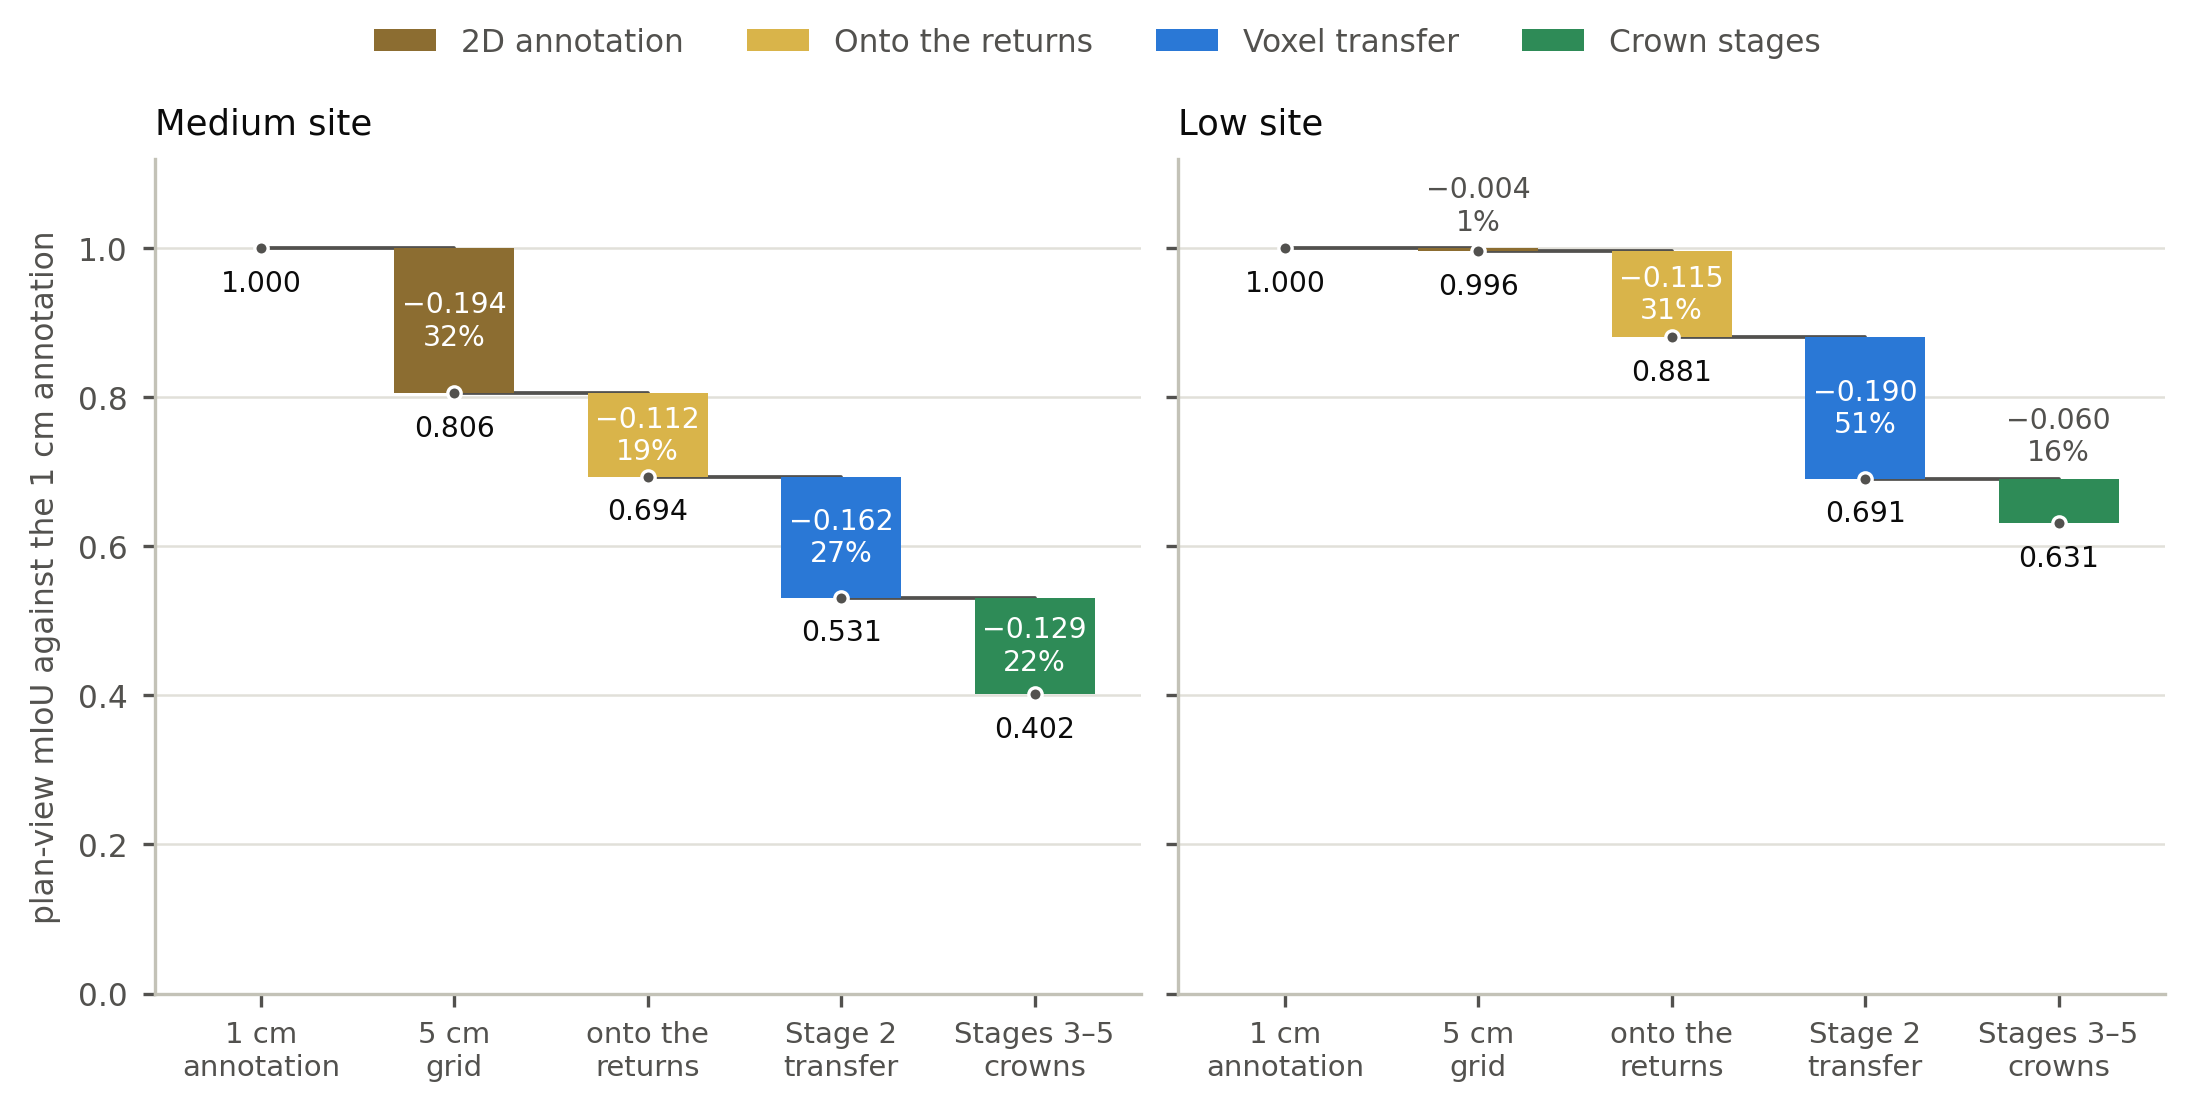

| Step | Part of the pipeline | Medium: mIoU | Medium: lost | Low: mIoU | Low: lost |
|---|---|---:|---:|---:|---:|
| The annotator's 1 cm raster | 2D annotation | 1.000 | – | 1.000 | – |
| 1 cm → 5 cm label grid | 2D annotation | 0.806 | -0.194 | 0.996 | -0.004 |
| 5 cm labels → labelled lidar returns | Onto the returns | 0.694 | -0.112 | 0.881 | -0.115 |
| Stage 2: voxel transfer (10 cm) | Voxel transfer | 0.531 | -0.162 | 0.691 | -0.190 |
| Stages 3–5: crown detection, refinement, vote | Crown stages | 0.402 | -0.129 | 0.631 | -0.060 |

Share of the total loss, step by step in the order above — **Medium** 32%, 19%, 27%, 22% (total 0.598); **Low** 1%, 31%, 51%, 16% (total 0.369).

In [2]:
figure("supplementary_error_budget",
       lambda p: fg.plot_error_budget(per_tile, label_quality, p))
display(Markdown(fg.error_budget_table(per_tile, label_quality)))

**Reading.**

- **The two sites fail in different places.** At the medium site the largest single component is
  not in the 3D pipeline at all: it is the 1 cm → 5 cm downsampling, which costs 0.194 of the
  0.598 total. A 3072 px tile at 1 cm does not divide into 5 cm cells (3072 × 0.01 / 0.05 =
  614.4), so 13 of 15 medium tiles land on a shifted grid. The low site's labels happen to
  align, lose 0.004 there, and are dominated instead by the voxel transfer.
- **So the error budget is not a property of the method alone.** Reporting only one site would
  have given a misleading account of which component matters.

The ladder says how much each step costs. It does not say what the error *is*, which is what a
reader needs in order to judge whether it matters — so the next table gives every step in its
own units, including the two the ladder cannot carry: delineation has no reference at all, and
polygon → 1 cm compares a vector against the raster that *is* the reference here.

In [3]:
display(Markdown(fg.error_sources_table(per_tile, label_quality)))

| Step | What it introduces | How it is measured | Medium | Low |
|---|---|---|---:|---:|
| Delineation | Where the annotator put each boundary | IoU of the class eroded against the class dilated by ±5 cm (a floor, not an estimate) | 0.321 / 0.254 | 0.508 / 0.547 |
| Delineation | Pixels claimed by two classes at once | Cross-class overlap, share of labelled area | 0.021% | 0.161% |
| Polygon → 1 cm raster | Rasterisation and draw-order resolution of overlaps | Class IoU, polygons rasterised exactly against the delivered 1 cm raster | 0.924 / 0.934 | 0.679 / 0.957 |
| 1 cm → 5 cm grid | Downsampling onto a grid that does not divide the tile | Class IoU against the majority of each cell's 1 cm sub-pixels | 0.806 / 0.804 | 0.996 / 0.997 |
| 1 cm → 5 cm grid | How far a feature's centre moves | Centroid RMSE per polygon | 0.012 m | 0.007 m |
| 5 cm labels → returns | Labelled cells holding no lidar return cannot be labelled | Plan-view mIoU of the labelled returns against the 5 cm raster they came from | 0.925 / 0.953 | 0.884 / 0.899 |
| 5 cm labels → returns | Returns on labelled cells missing from the structure cloud | Share of the lidar points on labelled cells, all tiles | 362 (0.005%) | 0 (0.000%) |
| 5 cm labels → returns | A plan-view lookup gives canopy returns the class beneath them | Share of Shrub returns above 1 m (see the class heights below) | see below | see below |
| Stage 1: height lookup | The nearest-neighbour search is in XY only | Largest shift in any class height range it causes, any tile | 0.017 m | 0.003 m |
| Stage 1: height lookup | Points beyond the 0.30 m matching radius | Share of structure points, any tile | 0.000% | 0.000% |
| Stage 2: voxel transfer | Labels extended past their 2D footprint | Share of the labels the transfer assigns | 12.5 / 11.8% | 16.0 / 15.9% |
| Stage 2: voxel transfer | Labels lost inside their 2D footprint | 100 − footprint recall, worst tile at any voxel size | 1.18% | 2.27% |
| Stage 2: voxel transfer | Voxels holding more than one class, settled by majority | Share of occupied voxels | 0.24 / 0.14% | 0.92 / 0.84% |
| Stage 4: crown refinement | Labels the polar refinement changes inside crowns | Share of all lidar points | 0.531 / 0.544% | 0.051 / 0.000% |
| Stage 5: crown vote | Crowns turned wholly mallee, overwriting Stage 4 | Crowns voted, of which mallee-majority | 816, 815 mallee | 8, 0 mallee |
| Stage 5: crown vote | Unlabelled returns promoted to mallee on height alone | Share of all lidar points | 1.824 / 1.852% | 0.020 / 0.000% |
| Stage 5: crown vote | Woody debris removed: it is not a growth form | Plan-view IoU, Stage 2 → final | 0.535 → 0.000 | 0.662 → 0.000 |

### 1.1 Most of the crown-stage loss is deliberate

The Stage 3–5 drop looks damaging until it is split by class. Woody debris is not a growth form,
and Stage 5 removes it at both sites by design.

In [4]:
display(Markdown(fg.class_attribution_table(per_tile)))

| Site | Class | Stage 2 | Final | Change | Share of the mIoU drop |
|---|---|---:|---:|---:|---:|
| Medium | Woody debris | 0.535 | 0.000 | -0.140 | 80% |
| Medium | Hummock grass | 0.582 | 0.582 | -0.000 | 0% |
| Medium | Shrub | 0.621 | 0.622 | +0.000 | -0% |
| Medium | Mallee | 0.844 | 0.703 | -0.036 | 21% |
| Medium | **All classes (mIoU)** | 0.648 | 0.472 | -0.176 | 100% |
| Low | Forb | 0.648 | 0.646 | -0.001 | 2% |
| Low | Woody debris | 0.662 | 0.000 | -0.059 | 98% |
| Low | Shrub | 0.747 | 0.746 | -0.000 | 1% |
| Low | Mallee | – | 0.000 | +0.000 | -0% |
| Low | **All classes (mIoU)** | 0.692 | 0.632 | -0.060 | 100% |

Removing woody debris accounts for **80%** of the medium site's Stage 3–5 loss and **98%** of the
low site's. Net of it, the crown stages cost 0.036 mIoU at the medium site — all of it through
mallee, where the crown vote reassigns whole crowns — and essentially nothing at the low site.

### 1.2 The one error source no IoU shows

The structure cloud is built by `maskclip/core.py` as

```text
filters.crop  →  filters.colorization (label raster → Classification)  →  filters.range [64:68]
```

`filters.colorization` is a **plan-view raster lookup with no height gate**: a return takes the
class of the 5 cm cell beneath it whatever its height. Every return in the air column above a
labelled cell therefore inherits that cell's class, so where a ground class lies under mallee
canopy, canopy returns are written with the ground class.

Scored in plan view this is invisible — the label is on the right cell. It shows in the class
height distribution instead, as an upper tail: a clean class barely moves from p95 to p99, a
contaminated one jumps, because the contamination is a thin tail rather than a shift of the
whole class.

In [5]:
display(Markdown(fg.class_height_table(profile)))

| Site | Class | Returns | p50 | p85 | p95 | p99 | Above 1 m |
|---|---|---:|---:|---:|---:|---:|---:|
| Medium | Woody debris | 497,779 | 0.05 m | 0.25 m | 2.35 m | 3.65 m | 11.9% |
| Medium | Hummock grass | 926,055 | 0.05 m | 0.15 m | 0.15 m | 0.35 m | 0.6% |
| Medium | Shrub | 249,675 | 0.15 m | 0.45 m | 0.65 m | 2.15 m | 1.6% |
| Medium | Mallee | 5,298,333 | 0.45 m | 1.75 m | 2.35 m | 3.45 m | 35.1% |
| Low | Forb | 1,357,474 | 0.05 m | 0.05 m | 0.05 m | 0.15 m | 0.6% |
| Low | Woody debris | 23,412 | 0.15 m | 4.15 m | 4.95 m | 5.85 m | 40.5% |
| Low | Shrub | 3,163,766 | 0.15 m | 0.25 m | 0.35 m | 0.55 m | 0.2% |

**Reading.**

- **Classes in the open are clean.** Forb and Hummock grass have nothing above them and are flat
  to p99 (0.05→0.15 m and 0.15→0.35 m), with under 1% of returns above 1 m.
- **Classes under canopy carry a tail.** Medium Shrub runs 0.65 m at p95 to **2.15 m** at p99.
  Those returns are mallee canopy above a shrub polygon, not tall shrubs.
- **Woody debris carries the heaviest tail** (11.9% medium, 40.5% low above 1 m) but never
  reaches the delivered labels: Stage 5 removes it, as section 1.1 shows.
- **Shrub is the growth form affected**, and it does survive to the final labels (IoU 0.622
  medium, 0.746 low).

**Why the pipeline is not changed for it.** A height cap cannot separate the tail cleanly:
medium Shrub's p99 (2.15 m) sits above Mallee's p85 (1.75 m), so any threshold that removes
canopy from shrub also removes genuine tall shrub. A height-gated lookup at the colorization
step would remove the error at source, and is recorded as the clearest available improvement
rather than applied here, since re-running the transfer would invalidate every downstream
product.

## 2. Voxel size (comment on 3.2.2)

> *The choice of 10 cm voxel size appears empirical. Could the authors provide a comparison of
> different voxel sizes (e.g. 5, 10, 15, 20, 25 cm) and include the results as a supplementary
> figure?*

The complete workflow was run at all five sizes on all 30 tiles. Panels (a)–(e) describe the
Stage-2 transfer itself; panel (f) the final labels.

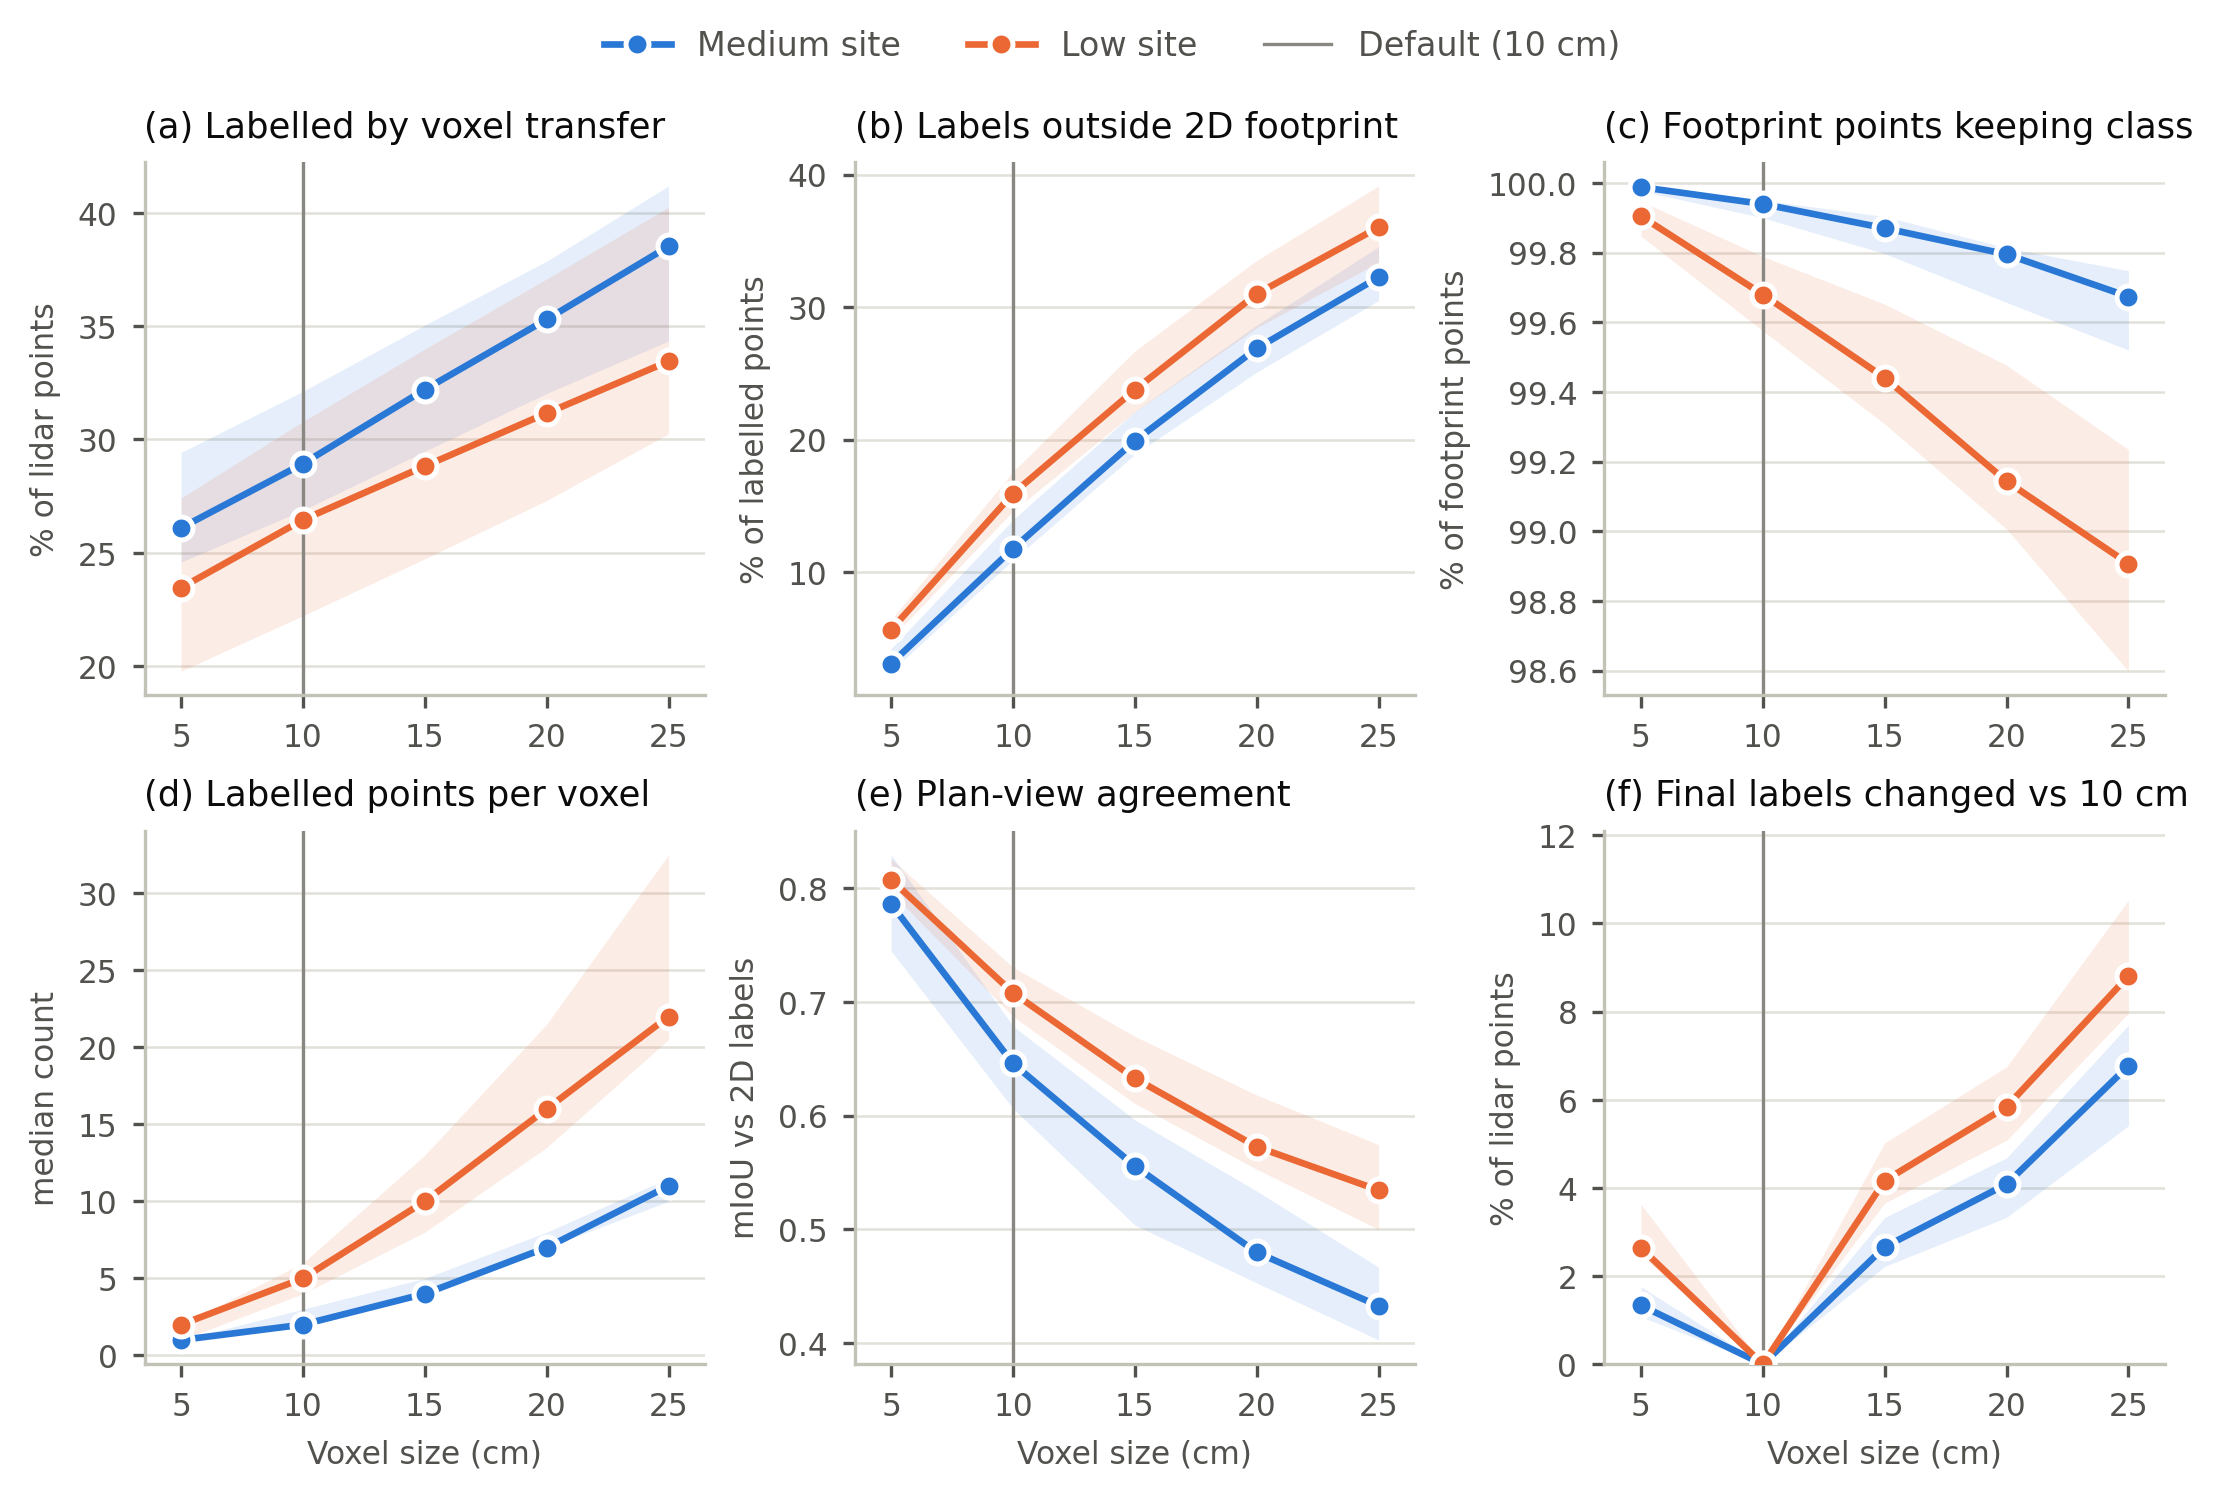

**The transfer (Stage 2)**

| Site | Voxel size (cm) | Labelled by transfer (%) | Outside footprint (%) | Footprint recall (%) | mIoU vs 5 cm input | Points per voxel | Single-point voxels (%) | Mixed-class voxels (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 27.2 / 26.1 | 3.5 / 3.1 | 99.97 / 99.99 | 0.787 / 0.786 | 1.0 / 1.0 | 67.2 / 69.3 | 0.04 / 0.02 |
| Medium | **10** | 30.0 / 28.9 | 12.5 / 11.8 | 99.89 / 99.94 | 0.648 / 0.646 | 2.3 / 2.0 | 33.9 / 35.2 | 0.24 / 0.14 |
| Medium | 15 | 33.0 / 32.2 | 20.6 / 19.9 | 99.80 / 99.87 | 0.556 / 0.556 | 4.4 / 4.0 | 20.4 / 20.7 | 0.59 / 0.39 |
| Medium | 20 | 35.9 / 35.3 | 27.0 / 26.9 | 99.69 / 99.80 | 0.495 / 0.480 | 7.6 / 7.0 | 14.7 / 15.1 | 1.04 / 0.78 |
| Medium | 25 | 38.8 / 38.5 | 32.5 / 32.3 | 99.57 / 99.67 | 0.446 / 0.433 | 11.6 / 11.0 | 11.6 / 11.7 | 1.64 / 1.29 |
| Low | 5 | 24.4 / 23.5 | 5.7 / 5.6 | 99.88 / 99.90 | 0.787 / 0.808 | 1.5 / 2.0 | 48.3 / 46.7 | 0.20 / 0.17 |
| Low | **10** | 27.4 / 26.4 | 16.0 / 15.9 | 99.68 / 99.68 | 0.692 / 0.708 | 5.0 / 5.0 | 17.6 / 16.8 | 0.92 / 0.84 |
| Low | 15 | 30.4 / 28.8 | 24.2 / 23.8 | 99.45 / 99.44 | 0.624 / 0.633 | 10.5 / 10.0 | 11.0 / 11.3 | 1.85 / 1.82 |
| Low | 20 | 33.3 / 31.2 | 30.8 / 31.0 | 99.21 / 99.14 | 0.572 / 0.572 | 17.2 / 16.0 | 8.4 / 8.3 | 2.80 / 2.74 |
| Low | 25 | 36.1 / 33.4 | 36.2 / 36.0 | 98.92 / 98.91 | 0.526 / 0.534 | 25.6 / 22.0 | 7.1 / 6.9 | 3.81 / 3.79 |

- Medium site: footprint recall on the lowest tile at any voxel size **98.82%**; at 5 cm the per-tile median of labelled points per voxel ranges 1–1.
- Low site: footprint recall on the lowest tile at any voxel size **97.73%**; at 5 cm the per-tile median of labelled points per voxel ranges 1–2.

**The final labels (after Stages 3–5)**

| Site | Voxel size (cm) | Labelled (%) | Outside footprint (%) | mIoU vs 5 cm input | mIoU vs 1 cm | Changed from 10 cm (%) |
|---|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 28.8 / 28.2 | 14.5 / 15.3 | 0.550 / 0.539 | 0.460 / 0.466 | 1.43 / 1.33 |
| Medium | **10** | 30.3 / 29.9 | 18.5 / 18.4 | 0.472 / 0.478 | 0.402 / 0.400 | 0.00 / 0.00 |
| Medium | 15 | 32.2 / 32.0 | 23.4 / 23.6 | 0.413 / 0.412 | 0.357 / 0.359 | 2.74 / 2.66 |
| Medium | 20 | 34.2 / 34.2 | 27.9 / 27.9 | 0.374 / 0.380 | 0.325 / 0.326 | 4.03 / 4.09 |
| Medium | 25 | 36.4 / 36.8 | 32.2 / 32.5 | 0.340 / 0.346 | 0.299 / 0.297 | 6.63 / 6.77 |
| Low | 5 | 24.4 / 23.5 | 6.0 / 5.8 | 0.713 / 0.796 | 0.712 / 0.795 | 3.09 / 2.64 |
| Low | **10** | 27.4 / 26.6 | 16.2 / 16.1 | 0.632 / 0.700 | 0.631 / 0.700 | 0.00 / 0.00 |
| Low | 15 | 30.4 / 29.0 | 24.3 / 23.8 | 0.572 / 0.623 | 0.571 / 0.622 | 4.49 / 4.17 |
| Low | 20 | 33.2 / 31.3 | 30.9 / 31.0 | 0.523 / 0.560 | 0.523 / 0.559 | 6.09 / 5.84 |
| Low | 25 | 36.1 / 33.5 | 36.2 / 36.0 | 0.482 / 0.502 | 0.482 / 0.502 | 9.62 / 8.81 |

In [6]:
figure("supplementary_voxel_size_sensitivity", lambda p: fg.plot_voxel_figure(per_tile, p))
display(Markdown("**The transfer (Stage 2)**\n\n"
                 + fg.table(per_tile, "voxel_size", fg.TRANSFER_COLUMNS)
                 + "\n\n" + fg.voxel_extremes(per_tile)))
display(Markdown("**The final labels (after Stages 3–5)**\n\n"
                 + fg.table(per_tile, "voxel_size", fg.FINAL_COLUMNS)))

### 2.1 What the sweep can and cannot settle

Agreement with the 2D labels falls **monotonically** with voxel size, at both sites and on every
measure. That is expected — the 2D annotation is the input as well as the reference, so any
extension counts against it — and it means the sweep documents a trade-off rather than locating
an optimum at 10 cm.

The table below puts coverage and spread on the same base, to show what each step up in voxel
size actually buys. `Outside footprint` is normally a share of *labelled* points, so it is
converted back to a share of all lidar points before differencing.

In [7]:
display(Markdown(fg.coverage_cost_table(per_tile)))

| Site | Voxel (cm) | Labelled (% of points) | Outside footprint (% of points) | Extra labelled vs 5 cm | Of which outside footprint |
|---|---:|---:|---:|---:|---:|
| Medium | 5 | 27.2 | 0.96 | +0.00 | – |
| Medium | **10** | 30.0 | 3.76 | +2.80 | 100% |
| Medium | 15 | 33.0 | 6.79 | +5.82 | 100% |
| Medium | 20 | 35.9 | 9.71 | +8.73 | 100% |
| Medium | 25 | 38.8 | 12.63 | +11.65 | 100% |
| Low | 5 | 24.4 | 1.40 | +0.00 | – |
| Low | **10** | 27.4 | 4.40 | +3.03 | 99% |
| Low | 15 | 30.4 | 7.38 | +6.03 | 99% |
| Low | 20 | 33.3 | 10.25 | +8.90 | 99% |
| Low | 25 | 36.1 | 13.08 | +11.73 | 100% |

**Every extra label a larger voxel buys lands outside the 2D footprint.** Going from 5 to 10 cm
labels 2.8% (medium) and 3.0% (low) more of the lidar points, and **99–100% of those additional
labels** sit on cells the annotation leaves unlabelled; the same holds at every further step.
Enlarging the voxel adds nothing inside the footprints — it extends labels laterally.

So no measure anchored to the 2D labels prefers 10 cm. The case for it has to come from
somewhere else.

### 2.2 The case for 10 cm: the spacing of the labelled returns

The merge can only act where a voxel holds **more than one** labelled return. The scale that
matters is therefore the spacing of the *labelled* returns, not of all returns: for a
planimetric density *d* per m², the mean spacing is 1/√*d*. A voxel narrower than that spacing
can only be expected to hold one labelled return, so roughly two spacings is the minimum for
reliable co-occupancy.

In [8]:
display(Markdown("**Voxel size relative to the spacing of labelled returns**\n\n"
                 + fg.spacing_table(per_tile)))
display(Markdown("**How the voxel would scale with survey density**\n\n"
                 + fg.sensor_scaling_table(per_tile)))

**Voxel size relative to the spacing of labelled returns**

| Site | Labelled returns per m² | Mean spacing (cm) | 5 cm | 10 cm | 15 cm | 20 cm | 25 cm |
|---|---:|---:|---:|---:|---:|---:|---:|
| Medium | 493 | 4.51 | 1.11× | 2.22× | 3.33× | 4.44× | 5.55× |
| Low | 321 | 5.58 | 0.90× | 1.79× | 2.69× | 3.58× | 4.48× |

**How the voxel would scale with survey density**

| Survey density | Labelled spacing (cm) | Voxel at 2× spacing (cm) |
|---|---:|---:|
| half as dense (0.5×) | 6.4–7.9 | 13–16 |
| this survey (1×) | 4.5–5.6 | 9–11 |
| twice as dense (2×) | 3.2–3.9 | 6–8 |

At 5 cm the voxel is about one spacing — narrower than the spacing at the low site — and holds a
median of one labelled return, with 67% (medium) and 48% (low) of voxels holding exactly one.
The transfer there reduces to projecting the 2D raster onto the points. At 10 cm it is roughly
two spacings: the median rises to 2.3 and 5.0, single-occupancy falls to 34% and 18%, and fewer
than 1% of voxels mix classes. Above 10 cm, voxels approach the size of the mapped features
(median polygon 0.076 m² at the medium site, ≈28 cm across) and mixed-class voxels grow steadily.

This turns the choice from an empirical one into a property of the survey, and the last table
states it as a rule that transfers to other surveys: **about twice the mean spacing of the
labelled returns**, which scales as the inverse square root of density.

### 2.3 The limit of that argument: density varies with height

The spacing above is a plan-view average, and a voxel is a cube: two returns a metre apart in
height never share a 10 cm cube however close they are in plan. Counts span three orders of
magnitude, so the axis is logarithmic.

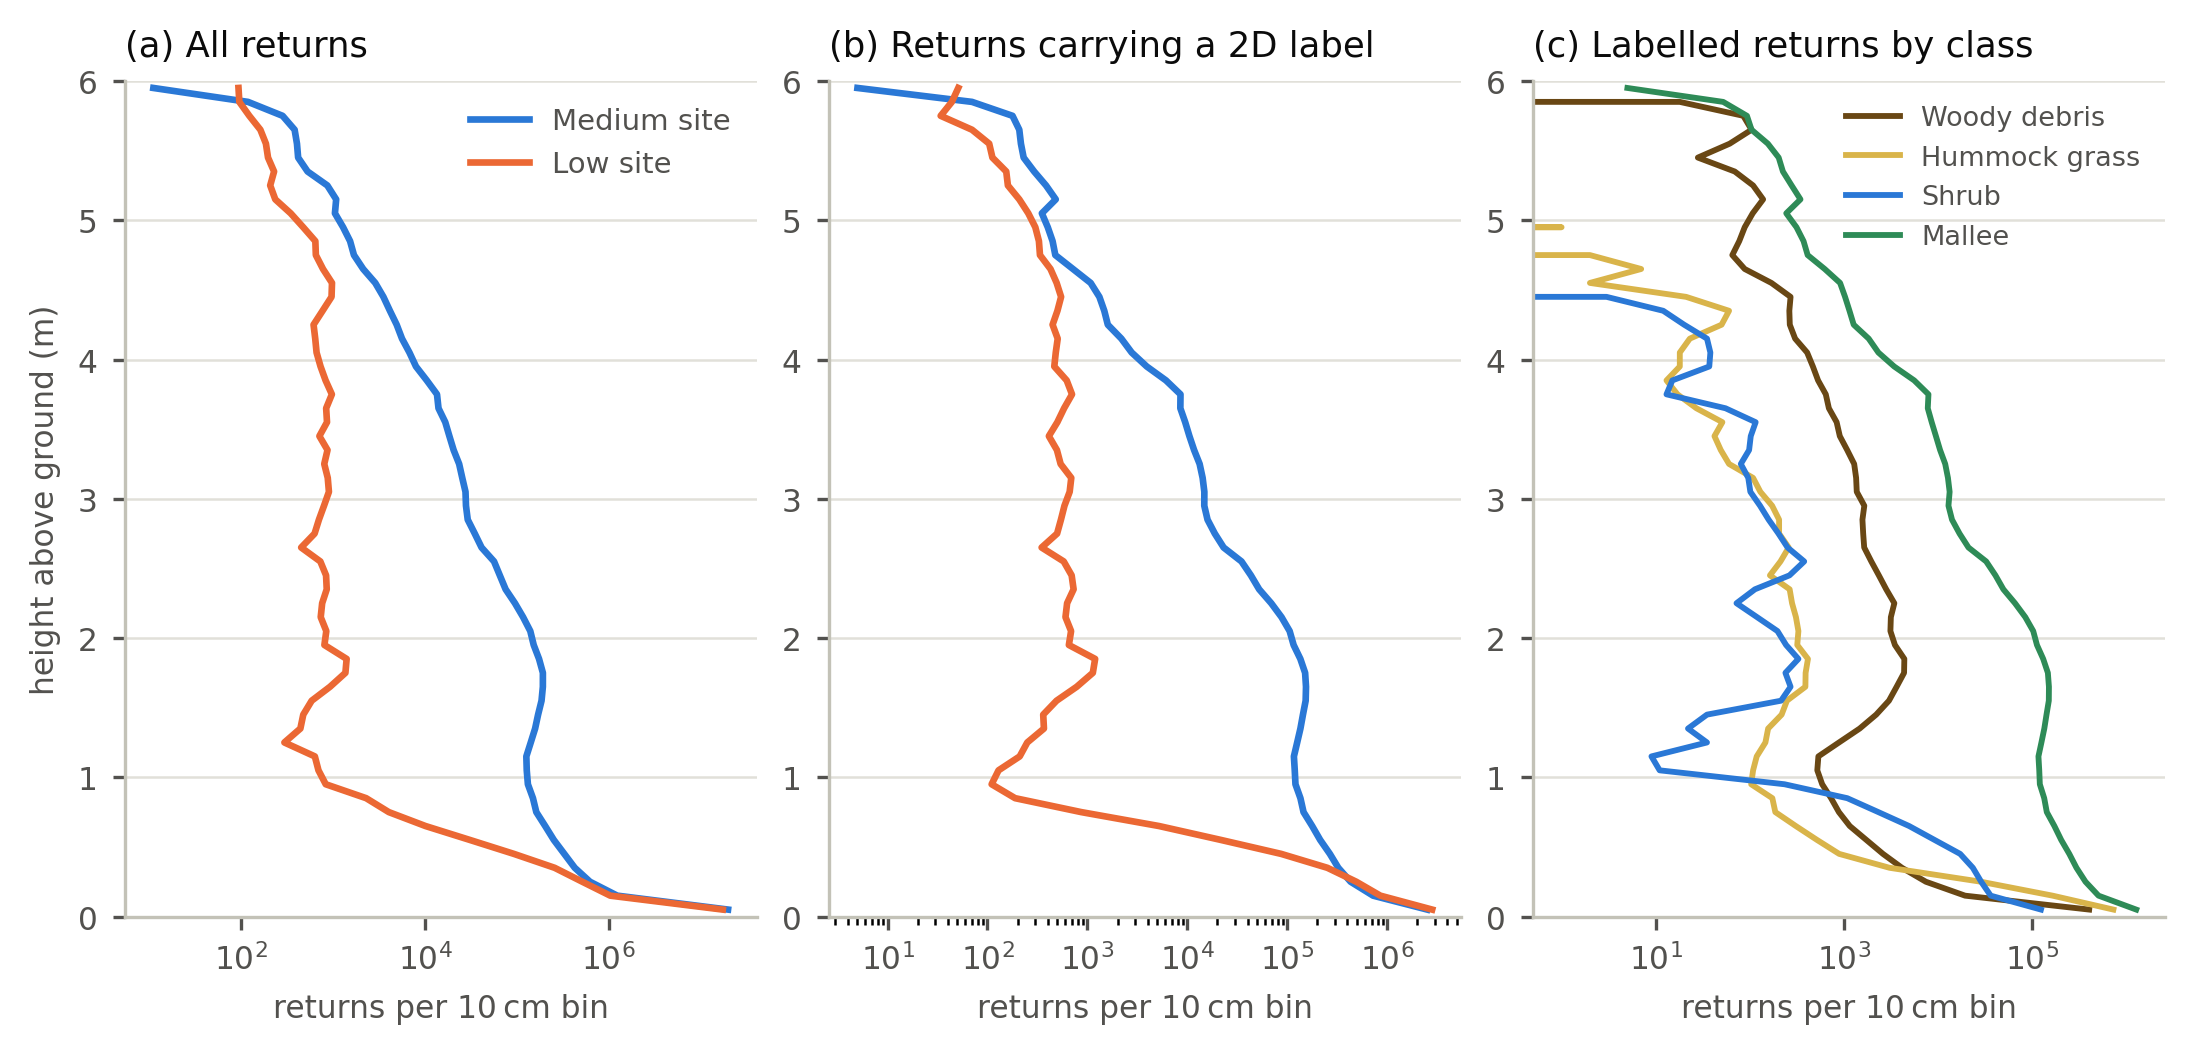

| Site | Band | All returns | Labelled returns | Labelled (%) | Labelled per m² |
|---|---|---:|---:|---:|---:|
| Medium | 0–10 cm (ground) | 19,939,976 | 2,511,074 | 12.6 | 177.4 |
| Medium | 10–50 cm (understorey) | 2,621,957 | 1,741,635 | 66.4 | 123.0 |
| Medium | 0.5–1.5 m | 1,625,540 | 1,430,794 | 88.0 | 101.1 |
| Medium | 1.5–3 m | 1,579,055 | 1,172,479 | 74.3 | 82.8 |
| Medium | >3 m (upper canopy) | 217,520 | 115,860 | 53.3 | 8.2 |
| Low | 0–10 cm (ground) | 17,496,215 | 2,812,597 | 16.1 | 198.7 |
| Low | 10–50 cm (understorey) | 1,907,211 | 1,681,147 | 88.1 | 118.8 |
| Low | 0.5–1.5 m | 50,606 | 29,369 | 58.0 | 2.1 |
| Low | 1.5–3 m | 12,374 | 10,143 | 82.0 | 0.7 |
| Low | >3 m (upper canopy) | 17,740 | 11,396 | 64.2 | 0.8 |

In [9]:
figure("supplementary_vertical_profile", lambda p: fg.plot_vertical_profile(profile, p))
display(Markdown(fg.vertical_table(profile)))

**Reading.**

- **The plan-view average hides a 60-fold range.** Labelled returns average 493 per m² at the
  medium site, but that is dominated by the ground: above 3 m the site carries only ~8 per m², a
  mean spacing of roughly 35 cm. A 10 cm voxel in the upper canopy will almost always hold a
  single labelled return, so the merge is weakest exactly where mallee sits.
- **The rule holds where the labels are.** Most labelled returns lie below 1.5 m, and there the
  spacing is a few centimetres, comfortably above the two-spacing minimum.
- **The low site is almost entirely low vegetation** — 2.1 labelled returns per m² above 0.5 m —
  consistent with its 2D labels carrying no mallee.

**Consequence.** No single voxel size satisfies the two-spacing rule at every height. 10 cm meets
it through the understorey, where the great majority of labelled returns lie, and falls short in
the upper canopy. A height-varying voxel would follow the density more closely; that is a change
to the method rather than a parameter value, and is not made here.

### 2.4 The same effect, drawn on a tile

The figure above counts the labels spread past their 2D footprint; this one draws them, in a 2 m
window with every lidar return seen from above. Two cautions: the grid squares are voxel
**columns**, so a grey return can share a square with blue ones while sitting at a different
height; and the window is chosen, not typical — it holds the most spread labels at 25 cm among
windows a quarter to three quarters labelled, so its percentages run above the site means.

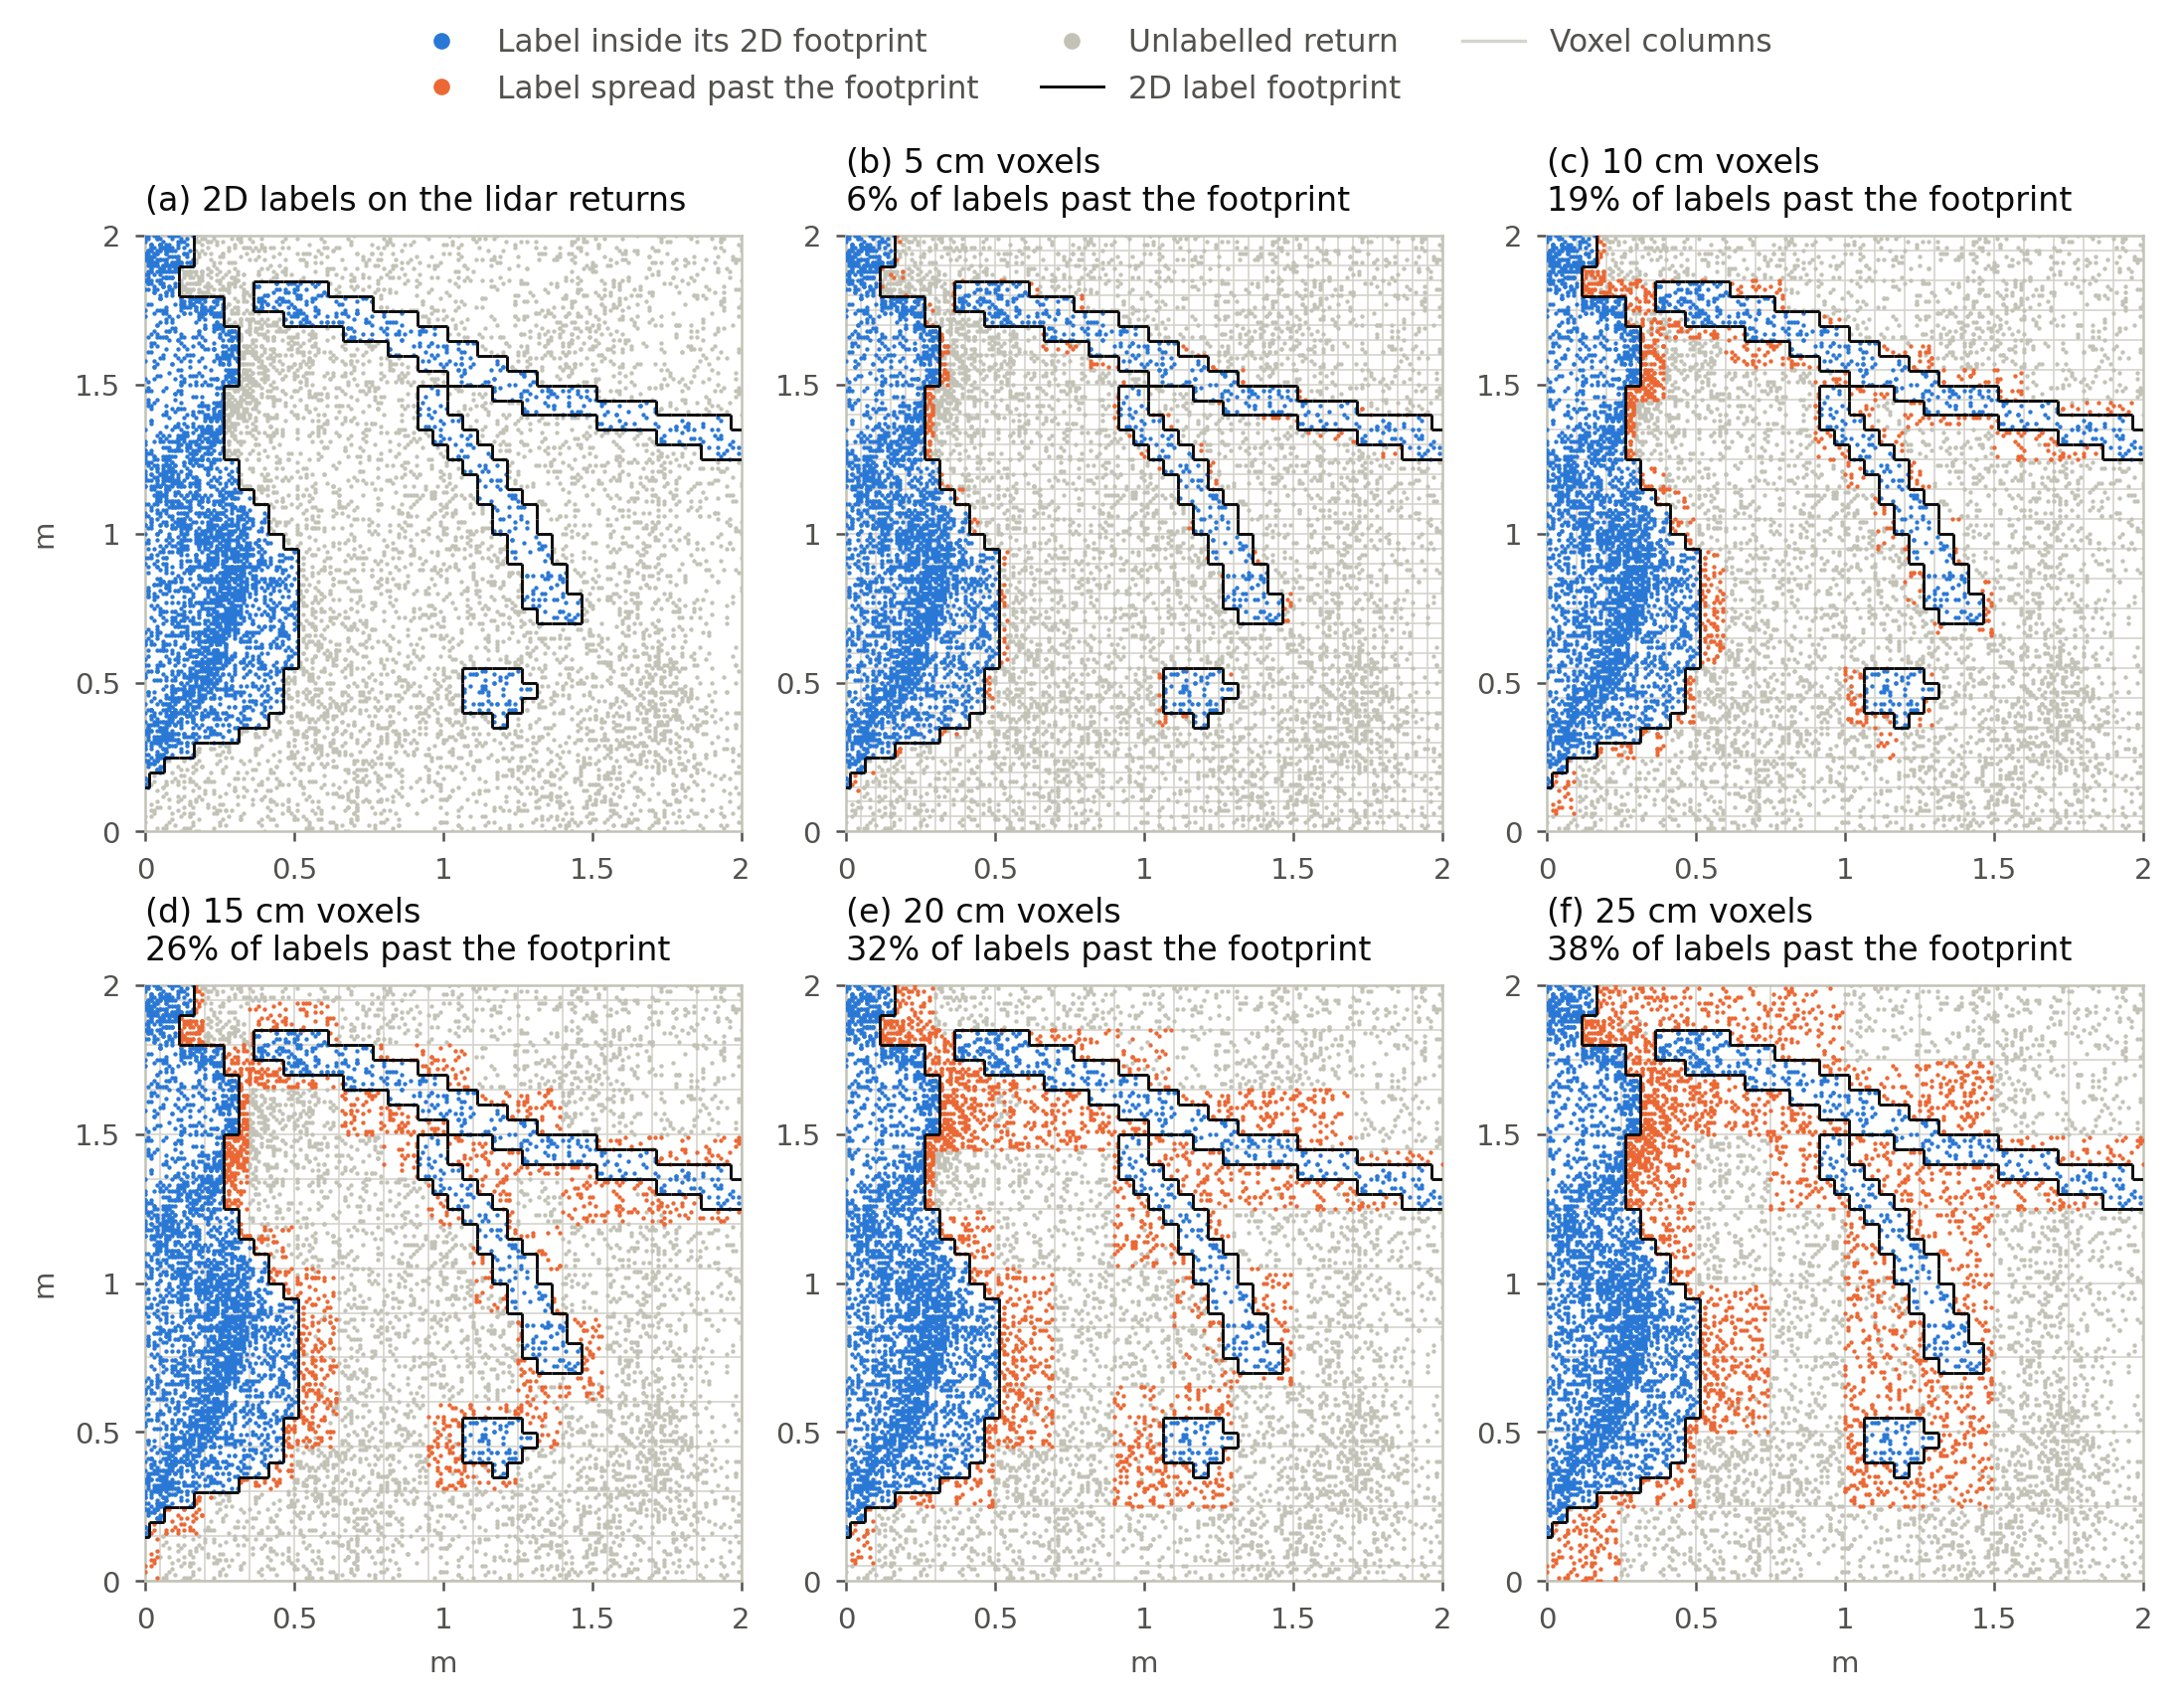

In [10]:
if (DATA_ROOT / SITE).exists():
    figure(f"voxel_transfer_tile{TILE}",
           lambda p: fg.plot_transfer_window(DATA_ROOT, SITE, TILE, p))
else:
    print(f"{DATA_ROOT / SITE} is not available here; showing the saved figure.")
    display(Image(filename=str(ASSETS / f"voxel_transfer_tile{TILE}.png")))

## 3. The 0.30 m matching radius

> *Please explain why the 0.30 matching radius was selected.*

The radius caps the nearest-neighbour search that gives each labelled point its height above
ground when the class height ranges are estimated (Stage 1). Those ranges feed the Stage-4 height
prior and the minimum crown height.

Because the labelled points **are** the lidar returns, every one has an exact counterpart in the
height-normalised cloud. The table below checks that on every tile rather than assuming it, and
also bounds the only approximation in the lookup: it matches in XY only, so where several returns
share a 1 cm XY position it can take the height of another return in the same column.

In [11]:
display(Markdown(fg.input_table(per_tile)))

| Check | Medium | Low |
|---|---:|---:|
| Tiles | 15 | 15 |
| Structure points with an exact Z_norm twin, lowest tile (%) | 100.000 | 100.000 |
| Largest XY match distance, any tile (m) | 0.000 | 0.000 |
| Structure points beyond the 0.30 m radius, any tile (%) | 0.000 | 0.000 |
| Heights taken from another return in the same column, range over tiles (%) | 8.3–19.1 | 4.3–10.5 |
| Largest class-range shift that causes, any tile (m) | 0.017 | 0.003 |
| Lidar points on labelled 5 cm cells missing from the structure cloud, all tiles | 362 (0.005%) | 0 (0.000%) |
| Plan-view mIoU of the 5 cm labels themselves (mean / median) | 0.925 / 0.953 | 0.884 / 0.899 |
| 5 cm labels lying outside the 1 cm footprint (mean / median, %) | 8.4 / 9.0 | 2.5 / 2.5 |
| Crown detection in the sweep (as the delivered labels were made) | `auto` | defaults |
| `auto` resolves to (min_tree_dist / smoothing_sigma), tiles | 0.8 m / 1.33 px on 15 | 0.8 m / 1.33 px on 4; 1.5 m / 1.00 px on 11 |
| Canopy point spacing `auto` starts from, range over tiles (m) | 0.022–0.032 | 0.010–0.022 |

Every labelled point is matched at **0.000 m on all 30 tiles**, and no point on any tile lies
beyond the radius. Its value therefore cannot affect the result — and the sweep confirms it:
radii of 0.01, 0.05, 0.10, 0.30 and 1.00 m give **identical labels on every tile**, 0.0000% of
points changed (figure in section 4, panels a and e). It is a guard against unmatched points
that this dataset never triggers.

## 4. Why these parameter values

> *It should be explained why various parameters such as voxel size (10 cm), weighting (1, 0.1),
> confidence threshold, and flip ratio were selected at their current values.*

Each parameter was varied across its range with the others at their defaults, on all 30 tiles.
The last two columns give the largest change any tested value made to the **final** labels, on
any tile.

In [12]:
display(Markdown(fg.answer_table(per_tile)))

| Parameter | Default | What it decides | Values tested | Medium: largest change (%) | Low: largest change (%) |
|---|---:|---|---|---:|---:|
| Voxel size | 10 cm | how far a 2D label extends to neighbouring returns | 5, 10, 15, 20, 25 | 9.24 | 16.28 |
| Matching radius | 0.3 m | how far a point may look for its height above ground | 0.01, 0.05, 0.1, 0.3, 1 | 0.00 | 0.00 |
| Out-of-range weight | 0.1 | how strongly a class outside its height range is penalised | 1, 0.5, 0.1, 0.01, 0 | 0.00 | 0.13 |
| min_conf | 0.3 | whether an unlabelled point inside a crown is filled | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.00 | 0.00 |
| min_flip_ratio | 1.5 | whether an existing label is overturned | 1, 1.25, 1.5, 2, 3 | 0.00 | 0.02 |

Only voxel size matters. The matching radius is never reached (section 3), and the three Stage-4
parameters act inside detected mallee crowns that Stage 5 then turns wholly to mallee — which is
why the final labels barely move. The next table shows that mechanism at the defaults.

In [13]:
display(Markdown(fg.crown_table(per_tile)))

| At the defaults | Medium | Low |
|---|---:|---:|
| Tiles with a detected crown | 15 of 15 | 4 of 15 |
| Crowns holding lidar points, put to the Stage-5 vote, all tiles | 816 | 8 |
| … of which more than half mallee, so turned wholly mallee | 815 | 0 |
| Mallee share of the least-mallee crown, any tile (%) | 50.0 | 0.0 |
| Lidar points inside crowns (mean / median, %) | 22.4 / 23.1 | 0.7 / 0.0 |
| Stage-4 labels changed (mean / median, % of points) | 0.531 / 0.544 | 0.051 / 0.000 |
| Stage-4 mean confidence, tiles with crowns (mean) | 0.9986 | 0.9908 |
| Points turned mallee by the vote (mean / median, %) | 0.34 / 0.34 | 0.00 / 0.00 |

At the medium site **815 of the 816 crowns** put to the Stage-5 vote were mallee-majority, so the
vote overwrote essentially every decision Stage 4 had made, and no tested setting changed a final
label there. The low site has no mallee in its 2D labels; on 4 of its 15 tiles the watershed's
height fallback still finds 8 crowns, none mallee-majority, so Stage-4 decisions survive there —
which is why its residual effects below are non-zero.

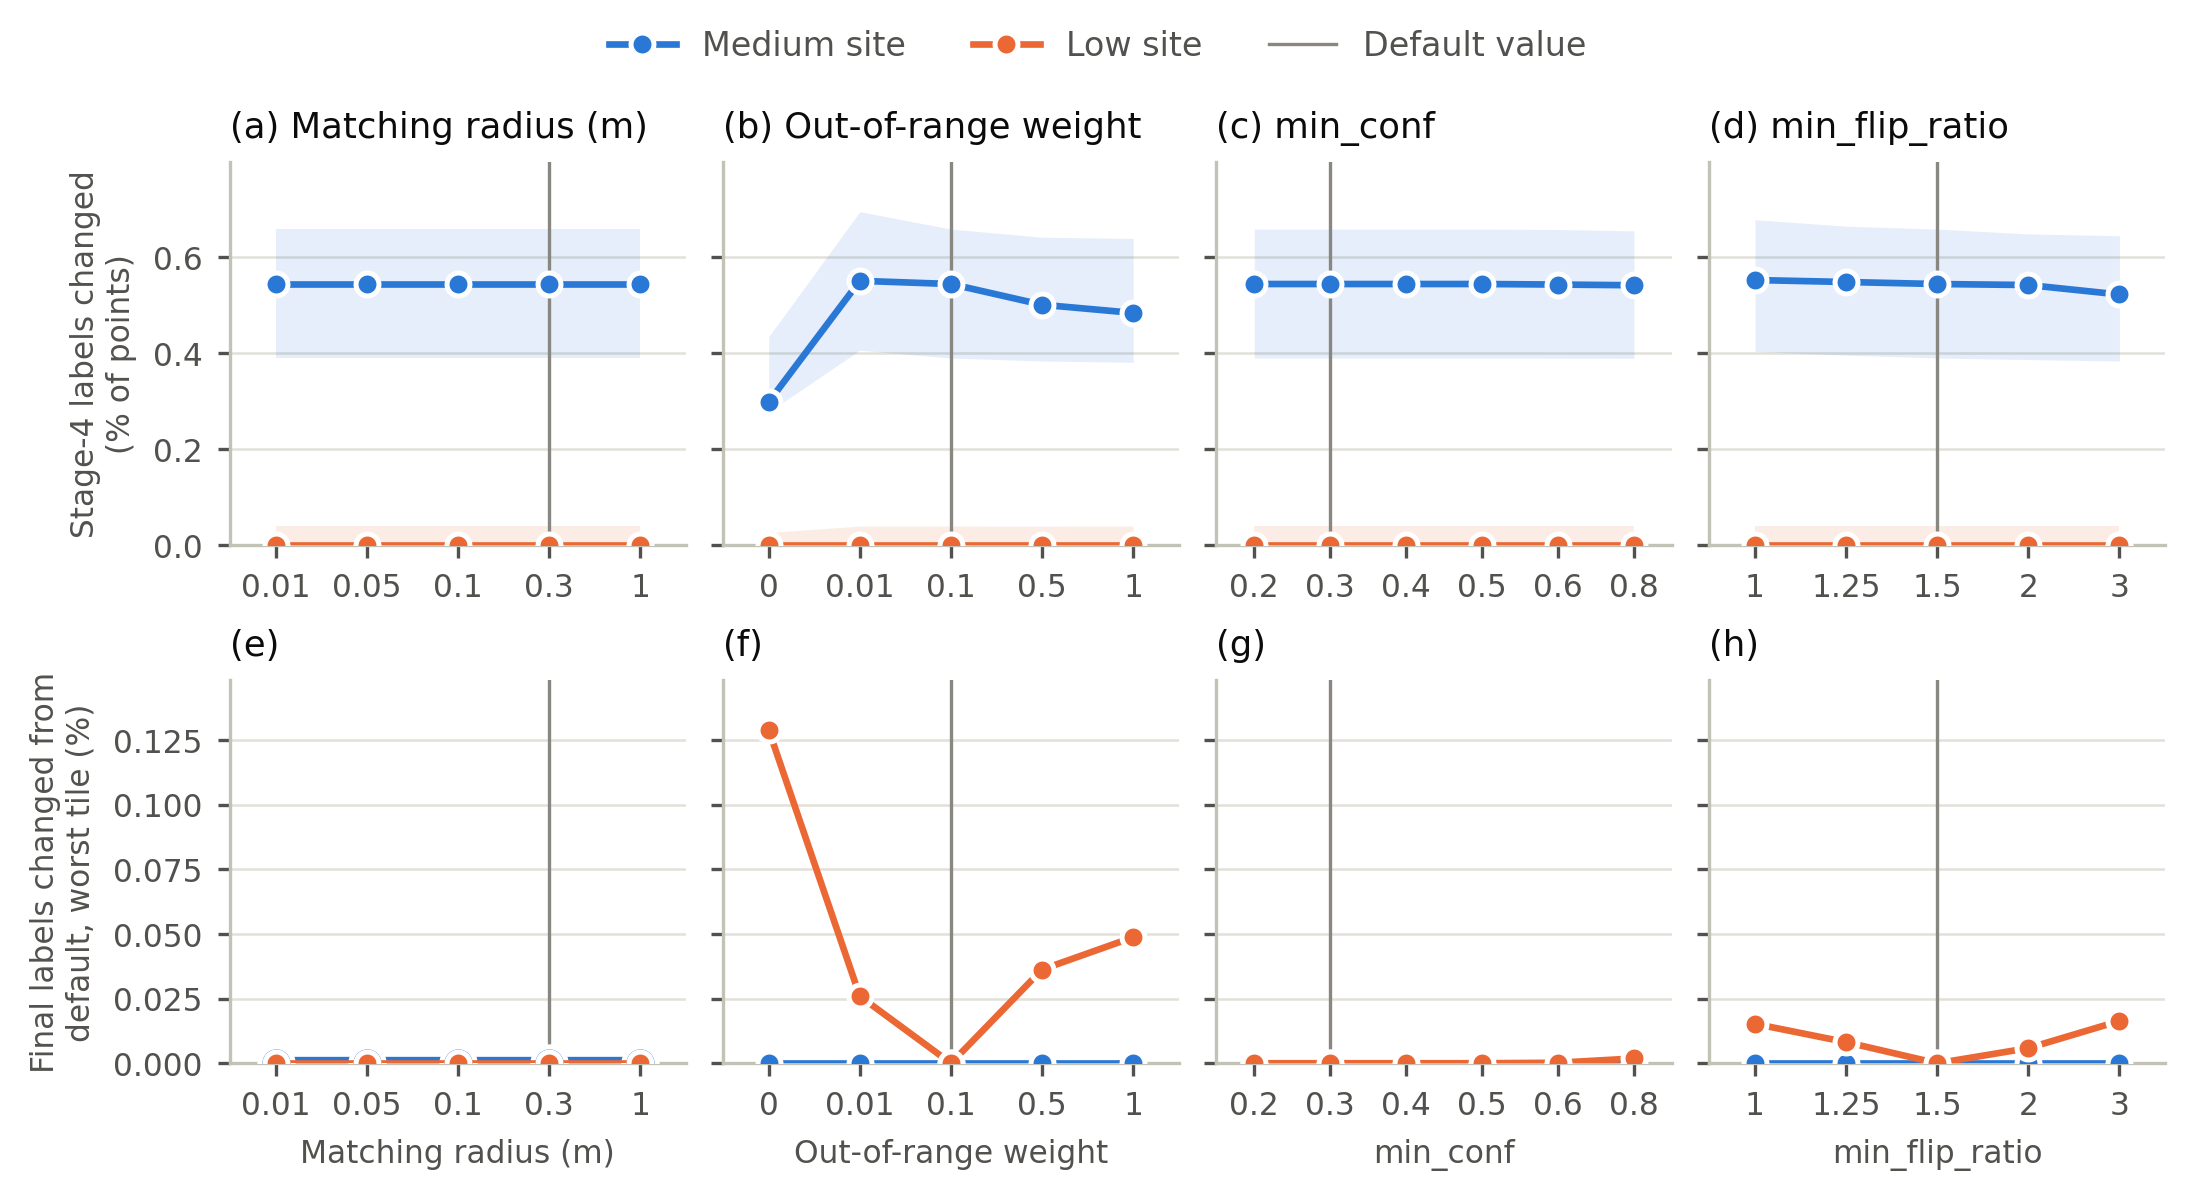

| Parameter | Values tested | Medium: worst tile (%) | Low: worst tile (%) |
|---|---|---:|---:|
| Matching radius (m) | 0.01, 0.05, 0.1, 0.3, 1 | 0.0000 | 0.0000 |
| Out-of-range weight | 1, 0.5, 0.1, 0.01, 0 | 0.0000 | 0.1288 |
| min_conf | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.0000 | 0.0018 |
| min_flip_ratio | 1, 1.25, 1.5, 2, 3 | 0.0000 | 0.0163 |

- Medium site: largest final-label change across 15 tiles and every value of the four parameters **0.0000%** of points; largest Stage-4 change 0.877%; tiles without a detected crown 0 of 15.
- Low site: largest final-label change across 15 tiles and every value of the four parameters **0.1288%** of points; largest Stage-4 change 0.408%; tiles without a detected crown 11 of 15.

In [14]:
figure("supplementary_parameter_sensitivity", lambda p: fg.plot_parameter_figure(per_tile, p))
display(Markdown(fg.worst_table(per_tile) + "\n\n" + fg.invariance_sentences(per_tile)))

Inside Stage 4, at the medium site, as `mean / median` across tiles. Below the table is the share
of evaluated points falling under each `min_conf` value on the worst tile — the check on whether
that gate ever binds.

In [15]:
display(Markdown(fg.stage4_table(per_tile) + "\n\n" + fg.min_conf_extremes(per_tile)))

| Parameter | Value | Stage-4 filled (%) | Stage-4 flipped (%) | Evaluated points below min_conf (%) | Final labels changed (%) |
|---|---:|---:|---:|---:|---:|
| Matching radius (m) | 0.01 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 0.05 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 0.1 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | **0.3** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 1 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0 | 0.278 / 0.265 | 0.062 / 0.037 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0.01 | 0.471 / 0.425 | 0.071 / 0.042 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | **0.1** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0.5 | 0.471 / 0.425 | 0.046 / 0.028 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 1 | 0.471 / 0.425 | 0.042 / 0.028 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.2 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | **0.3** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.4 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.5 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.6 | 0.471 / 0.424 | 0.060 / 0.036 | 0.088 / 0.059 | 0.000 / 0.000 |
| min_conf | 0.8 | 0.469 / 0.424 | 0.060 / 0.036 | 0.293 / 0.191 | 0.000 / 0.000 |
| min_flip_ratio | 1 | 0.471 / 0.425 | 0.069 / 0.041 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 1.25 | 0.471 / 0.425 | 0.063 / 0.038 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | **1.5** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 2 | 0.471 / 0.425 | 0.054 / 0.034 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 3 | 0.471 / 0.425 | 0.047 / 0.032 | 0.000 / 0.000 | 0.000 / 0.000 |

- Medium site, evaluated points below `min_conf` on the worst tile: 0.2: 0.0000%, 0.3: 0.0000%, 0.4: 0.0011%, 0.5: 0.0026%, 0.6: 0.2672%, 0.8: 0.9791%.
- Low site, evaluated points below `min_conf` on the worst tile: 0.2: 0.0000%, 0.3: 0.0000%, 0.4: 0.0000%, 0.5: 0.0000%, 0.6: 1.0095%, 0.8: 4.5839%.

**What fixes each value.** Each is fixed by what breaks at the ends of its range, not by tuning:

- **Height-prior weights (1, 0.1).** The weighted shares are renormalised, so only their *ratio*
  matters: a class outside its height range must be ten times as frequent in the bin to be
  assigned. A weight of 1 disables the prior; a weight of 0 makes it a veto, which would forbid
  each class for the 30% of its own points a 15th–85th percentile range excludes by construction
  — in the sweep it removed 41% of Stage-4 fills (0.471% → 0.278% of points).
- **`min_conf` = 0.3.** The most probable of *k* classes always scores at least 1/*k*, so 0.3
  accepts any bin holding up to three classes and rejects only near-ties among four or five. It
  never bound: probabilities average 0.999 and no evaluated point on any tile fell below 0.3.
- **`min_flip_ratio` = 1.5.** In a two-class bin this is a 60:40 majority rather than a bare one,
  so a label inherited from the 2D annotation is not reversed on a near-tie.

The replies that put these into prose are in
[`response_to_reviewers.md`](response_to_reviewers.md), together with four methodological
decisions the measurements expose but cannot make.

## 5. Regenerating

```bash
cd phase_4_3D_lidar_prep/step_3_structure_class/reviewer_response

# the measurements: ~660 pipeline runs, about 25 min with 16 workers, plus the profile
python sensitivity.py all --workers 16

# figures and tables, from the three CSVs
python figures.py
```

`sensitivity.py` takes `--sites`, `--tiles` and `--parameters` to restrict a run, and
`--data-root` (default `/mnt/d/paper2/data/calperumResearch`). Only these inputs are needed,
about 2.1 GB, at the same relative paths:

- `lidar/clipped/raster/z_norm/csf`
- the structure clouds: `lidar/clipped/mask/coreg/icp_top` for DD0001, `…/coreg/icp` for DD0011
- the `annotation_raster` directory and its `downsample_5cm_nearest` subdirectory
- `lidar/clipped/validation/label_quality/<site>_qa_summary.csv`, written by phase 3 step 3

Over the WSL mount of `D:` the workers spend much of their time waiting on reads; the recorded
run used a local copy passed as `--data-root`.

Set `REDRAW = True` in the setup cell to have this notebook redraw each figure rather than show
the saved PNG. `figures.py --voxel-volumes` additionally draws the 3D voxel-geometry figure,
which shows how coarse each grid is but nothing about the labels.